<div style="padding:20px; border-radius:6px; background-color:#ffe6e6; color:#b30000; border-left:5px solid #b30000;">
<b>Jalankan notebook ini dengan environment <code>mandala_env</code>.</b><br/>
Siapkan <code>VAULT_TOKEN</code> di file <code>.env</code> pada <b>root workdir proyek Anda</b> (atau export di environment).
</div>

# Tutorial: Akses Data INACAWO via Mandala

Marine Data Lake (**Mandala**) menyimpan observasi MMS1 dan dataset model (termasuk INACAWO)
di object storage. Di Mandalahub, Anda membaca data lewat protokol **S3** sebagai
**Zarr / zcollection** — tanpa mengunduh file NetCDF utuh ke workspace.

Notebook ini melanjutkan materi OPeNDAP: fokus living archive, catalog Mandala,
dan satu case study plot bergaya operasional OFS.


## 1. Apa itu Mandala / Mandalahub / Zarr?

| Konsep | Arti singkat |
|---|---|
| **Data lake** | Penyimpanan fleksibel; data masuk tanpa wajib transform penuh dulu |
| **Mandala** | Data lake maritim BMKG (observasi + NWP) di S3 on-prem |
| **Zarr / zcollection** | Format chunked; baca hanya potongan yang dibutuhkan, cocok object storage |
| **Mandalahub** | JupyterHub analisis di jaringan lokal ke S3 Mandala |

Untuk INACAWO di Mandala: arsip **living FULL** cycle **00Z & 12Z** — ditumpuk / di-override
tiap cycle terbaru (bukan snapshot beku per run). Hindcast multi-dekade juga tersedia
lewat catalog `model_hindcast`.

**Bedakan dari OPeNDAP:** OPeNDAP = file NetCDF forecast retensi pendek + subset remote;
Mandala = arsip panjang + I/O paralel Zarr di Mandalahub.


## 2. Struktur data Mandala vs OPeNDAP

Keduanya berasal dari postproc ilmiah INACAWO yang sama, tetapi **kemasan berbeda**.
Selalu cek `.attrs` sebelum membandingkan angka antar sumber.

### Dimensi & naming
| | OPeNDAP | Mandala (contoh) |
|---|---|---|
| Waktu | `time` | `TSTEP` |
| Vertikal | `depth` (Flows) / — | `LAY` (layer; di WRF = level tekanan) |
| Spatials | `lat`, `lon` | `ROW`, `COL` (+ coord `lat`/`lon`) |
| SWH | `hs` | `sig_wave_height` |
| Wind U/V | `uwnd` / `vwnd` | `U_WIND` / `V_WIND` (`inacawo_wrf_3d`) |
| Current | `u` / `v` | `ubar_eastward` (+ pasangan V bila ada) |
| SSH | `zeta` | `zeta` |

### Collection yang dipakai di tutorial
| Path collection | Isi tipikal |
|---|---|
| `mandala-prod1/datalake/model/collections/inacawo_ocean_2d` | ocean/wave 2D surface fields |
| `mandala-prod1/datalake/model/collections/inacawo_wrf_3d` | atmosfer 3D |

### Satuan & arah (ingat!)
- Angin OPeNDAP Atmos sering **m/s**; file Wave OPeNDAP bisa **knots**.
- Plot OFS menampilkan angin dalam **knot** (`× 1.94384` dari m/s).
- Arus OPeNDAP biasanya **cm/s**; di Mandala/plotter kadang m/s lalu `×100` — **cek attrs + magnitudo**.
- Komponen `*_eastward` / `*_northward` = vektor *ke arah* (CF).
- Field `*_dir`: pastikan konvensi from/to; helper `plot_ofs_map` mengikuti **ofs-plotter**.


## 3. Import & koneksi S3 via Vault

Jangan hard-code Access Key / Secret Key di notebook.
Token Vault bisa di-set di environment atau di cell di bawah (jangan commit token).


In [1]:
import os
from datetime import datetime
from pathlib import Path
from typing import Literal

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zcollection as zc
import zcollection.fs_utils as zc_fs
import mandala

from training_ofs import (
    find_project_root,
    load_project_env,
    load_s3_options_from_vault,
    plot_ofs_map,
    list_params,
)

# Portable: each participant workdir has its own clone + .env
PROJECT_ROOT = find_project_root()
ENV_PATH = load_project_env(required_keys=("VAULT_TOKEN",))
VAULT_TOKEN = os.environ["VAULT_TOKEN"]

print("Project root:", PROJECT_ROOT)
print("Loaded env:", ENV_PATH if ENV_PATH.is_file() else "(env vars only)")

s3_options = load_s3_options_from_vault(token=VAULT_TOKEN)

fs = fsspec.filesystem(
    "s3",
    key=s3_options["key"],
    secret=s3_options["secret"],
    client_kwargs=s3_options["client_kwargs"],
)
fs


ERROR 1: PROJ: proj_create_from_database: Open of /opt/tljh/user/envs/mandala_env/share/proj failed


Project root: /home/jupyter-tyo/training-ofs-2026
Loaded env: /home/jupyter-tyo/training-ofs-2026/.env


## 4. Catalog Mandala

Catalog memetakan dataset observasi / model / hindcast.
- `obs` → observasi MMS1
- `model` → living forecast archive (termasuk INACAWO operasional)
- `model_hindcast` → hindcast (retensi panjang; hati-hati load tanpa filter)


In [2]:
def get_catalog(
    database: Literal["obs", "model", "model_hindcast"],
    s3_options: dict,
):
    catalog = {
        "obs": "catalog.json",
        "model": "catalog.json",
        "model_hindcast": "catalog_hindcast.json",
    }.get(database, "catalog.json")
    if database == "model_hindcast":
        database = "model"
    catalog_path = os.path.join("mandala-prod1/datalake/", database, catalog)
    return mandala.MandalaCatalog(
        path=catalog_path,
        protocol="s3",
        options=s3_options,
    )


In [3]:
catalogobs = get_catalog("obs", s3_options)
catalogobs


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/obs/collections/arvor_c,ARVOR_C,2022-02-24T00:00:00,2026-10-22T03:07:00,2026-10-22T03:32:25
mandala-prod1/datalake/obs/collections/arvor_i,ARVOR_I,2022-02-25T08:29:21,2026-10-23T13:04:03,2026-10-23T13:11:39
mandala-prod1/datalake/obs/collections/svp,SVP,2022-02-22T08:00:00,2026-11-02T12:06:00,2026-10-23T23:17:25
mandala-prod1/datalake/obs/collections/vaws,VAWS,2000-01-01T01:00:00,2068-08-12T03:40:00,2026-10-24T17:16:04
mandala-prod1/datalake/obs/collections/maws,MAWS,2022-04-25T09:40:00,2026-10-23T23:10:00,2026-10-24T17:15:06
mandala-prod1/datalake/grid/collections/radar/bada,RADAR_TOTAL_BADA,1971-12-31T20:51:24,2026-10-23T22:30:00,2026-10-24T17:16:11
mandala-prod1/datalake/grid/collections/radar/sega,RADAR_TOTAL_SEGA,1973-02-07T11:11:24,2026-10-23T22:30:00,2026-10-24T17:16:19


In [4]:
catalogmodel = get_catalog("model", s3_options)
catalogmodel


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_ocean_2d,INACAWO_OCEAN_2D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T07:57:12
mandala-prod1/datalake/model/collections/inacawo_wrf_2d,INACAWO_WRF_2D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T07:59:49
mandala-prod1/datalake/model/collections/inacawo_ocean_3d,INACAWO_OCEAN_3D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T08:34:42
mandala-prod1/datalake/model/collections/inacawo_wrf_3d,INACAWO_WRF_3D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T09:27:13
mandala-prod1/datalake/model/collections/inawaves,INAWAVES,2024-10-17T12:00:00,2026-09-22T09:00:00,2026-09-07T00:20:55
mandala-prod1/datalake/model/collections/inaflows,INAFLOWS,2024-10-18T00:00:00,2026-09-15T21:00:00,2026-09-06T21:20:38
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_2d,INACAWO_REALTIME_OCEAN_2D,2026-10-27T00:00:00,2026-10-31T07:00:00,2026-10-28T07:56:25
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_2d,INACAWO_REALTIME_WRF_2D,2026-10-27T00:00:00,2026-10-30T20:00:00,2026-10-28T07:59:02
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_3d,INACAWO_REALTIME_OCEAN_3D,2026-10-27T00:00:00,2026-10-31T06:00:00,2026-10-28T08:22:34
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_3d,INACAWO_REALTIME_WRF_3D,2026-10-27T00:00:00,2026-10-30T19:00:00,2026-10-28T09:10:27


In [5]:
catalogmodelhindcast = get_catalog("model_hindcast", s3_options)
catalogmodelhindcast


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_2d,INACAWO_HINDCAST_OCEAN_2D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-08-10T05:21:13
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_2d,INACAWO_HINDCAST_WRF_2D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-09-07T02:34:59
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_3d,INACAWO_HINDCAST_WRF_3D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-10-09T01:31:44
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_3d,INACAWO_HINDCAST_OCEAN_3D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-10-09T04:22:36


## 5. Membaca collection INACAWO dengan zcollection

Semua dataset disimpan sebagai **zcollection** (di atas Zarr), efisien diproses dengan `xarray`.

**Wajib:** pakai `filters` tanggal sempit. Load tanpa filter bisa menarik ratusan partition.


In [6]:
fs.invalidate_cache()
ocean2d_collection = zc.open_collection(
    path="mandala-prod1/datalake/model/collections/inacawo_ocean_2d",
    mode="r",
    filesystem=zc_fs.get_fs(filesystem=fs),
)

# Jaga window kecil agar ramah sistem (sesuaikan jika partition berubah)
date_filter = (
    "(year == 2026 and month == 9 and day >= 12) or "
    "(year == 2026 and month == 9 and day <= 13)"
)

dset = ocean2d_collection.load(delayed=True, filters=date_filter).to_xarray()
dset


<xarray.Dataset>
Dimensions:           (TSTEP: 720, LAY: 1, ROW: 1201, COL: 2201)
Coordinates:
  * TSTEP             (TSTEP) datetime64[ns] 2026-09-01 ... 2026-09-30T23:00:00
  * ROW               (ROW) float64 -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL               (COL) float64 90.0 90.02 90.05 90.08 ... 144.9 145.0 145.0
Dimensions without coordinates: LAY
Data variables: (12/29)
    peak_wave_len     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    net_fresh_flux    (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    mean_wave_len     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    swrad             (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    RUNTIME           (TSTEP) datetime64[ns] dask.array<chunksize=(24,), meta=np.ndarray>
    peak_wave_period  (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    ...                ...
    ubar_eastward     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    net_salt_flux     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    temp_sur          (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    lon               (COL) float32 dask.array<chunksize=(1101,), meta=np.ndarray>
    geographic        |S1 dask.array<chunksize=(), meta=np.ndarray>
    lat               (ROW) float32 dask.array<chunksize=(601,), meta=np.ndarray>

### Inspect atribut (latihan)

Bandingkan nama variabel Mandala dengan short name OPeNDAP dari tutorial sebelumnya.


In [7]:
def summarize_mandala(ds: xr.Dataset) -> pd.DataFrame:
    rows = []
    for name, da in ds.data_vars.items():
        rows.append(
            {
                "variable": name,
                "dims": tuple(da.dims),
                "units": da.attrs.get("units"),
                "long_name": da.attrs.get("long_name") or da.attrs.get("var_desc"),
                "standard_name": da.attrs.get("standard_name"),
            }
        )
    return pd.DataFrame(rows).sort_values("variable")

summarize_mandala(dset).head(20)


,variable,dims,units,long_name,standard_name
4,RUNTIME,"(TSTEP,)",None,forecast reference time aka run time or analys...,forecast_reference_time
27,geographic,(),None,None,None
28,lat,"(ROW,)",degrees_north,latitude,latitude
26,lon,"(COL,)",degrees_east,longitude,longitude
19,mean_wave_dir,"(TSTEP, LAY, ROW, COL)",Degrees,mean_wave_dir,sea_surface_mean_wave_from_direction
2,mean_wave_len,"(TSTEP, LAY, ROW, COL)",m,mean_wave_len,sea_surface_mean_wave_length
1,net_fresh_flux,"(TSTEP, LAY, ROW, COL)",m s-1,net_fresh_flux,sea_surface_upward_net_freshwater_flux
17,net_latent_hf,"(TSTEP, LAY, ROW, COL)",W m-2,net_latent_hf,sea_surface_upward_net_latent_heat_flux
24,net_salt_flux,"(TSTEP, LAY, ROW, COL)",m s-1,net_salt_flux,sea_surface_net_salt_flux
7,peak_wave_dir,"(TSTEP, LAY, ROW, COL)",Degrees,peak_wave_dir,sea_surface_peak_wave_from_direction


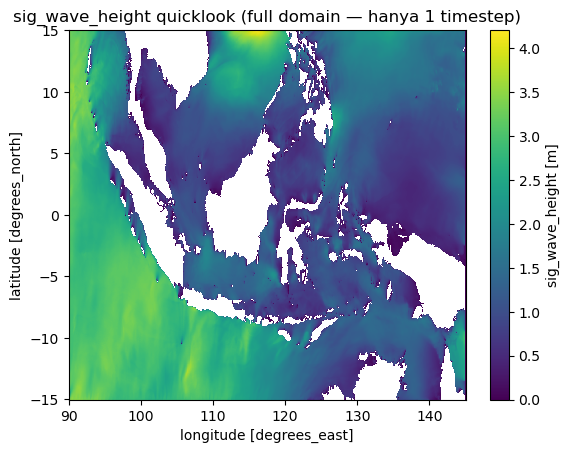

In [8]:
# Quicklook bawaan xarray (bukan layout OFS)
dset.isel(TSTEP=10).sig_wave_height.plot()
plt.title("sig_wave_height quicklook (full domain — hanya 1 timestep)")
plt.show()


## 6. Case study: SWH Laut Jawa dari living archive

**Skenario.** Ambil `sig_wave_height` untuk window singkat, crop ke Laut Jawa,
lalu plot dengan **layout OFS** (`param='swh'`) — sama gaya produk operasional.

Crop spatial **setelah** load bertarget filter tanggal, sebelum `plot_ofs_map`.


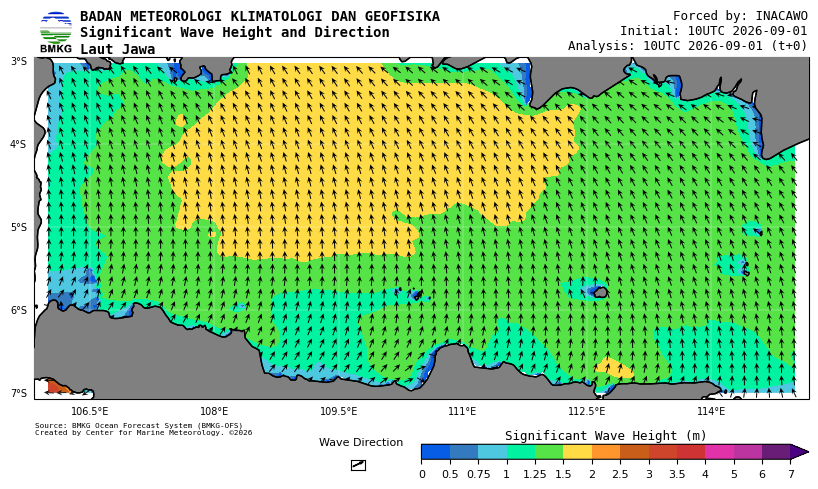

In [9]:
# Ambil 1 timestep di tengah window, crop Laut Jawa
sample = dset["sig_wave_height"].isel(TSTEP=min(10, dset.sizes["TSTEP"] - 1))
# ROW/COL are lat/lon coordinates on this collection
sample = sample.sel(ROW=slice(-7.0, -3.0), COL=slice(106.0, 115.0))

# Flatten LAY if present
if "LAY" in sample.dims:
    sample = sample.isel(LAY=0)

lat = sample["ROW"].values if "ROW" in sample.coords else sample["lat"].values
lon = sample["COL"].values if "COL" in sample.coords else sample["lon"].values
field = np.squeeze(sample.values)

# Timestamp for OFS header
tstamp = pd.to_datetime(sample["TSTEP"].values) if "TSTEP" in sample.coords else None
if tstamp is None and "TSTEP" in dset.coords:
    tstamp = pd.to_datetime(dset["TSTEP"].values[min(10, dset.sizes["TSTEP"] - 1)])
baserun = pd.Timestamp(tstamp).to_pydatetime() if tstamp is not None else datetime.utcnow()

# Optional direction if available on same timestep
direction = None
for cand in ("sig_wave_dir", "mean_wave_dir", "wave_dir", "dir"):
    if cand in dset:
        d = dset[cand].isel(TSTEP=min(10, dset.sizes["TSTEP"] - 1))
        if "LAY" in d.dims:
            d = d.isel(LAY=0)
        d = d.sel(ROW=slice(-7.0, -3.0), COL=slice(106.0, 115.0))
        direction = np.squeeze(d.values)
        break

fig, ax = plot_ofs_map(
    lon,
    lat,
    field,
    param="swh",
    direction=direction,
    baserun=baserun,
    forecast=baserun,
    wind_input="INACAWO",
    map_area="Laut Jawa",
    quiver_skip=6,
)
plt.show()


### Interpretasi singkat

Catat tinggi gelombang signifikan di Laut Jawa pada waktu sample:
apakah kondisi relatif tenang / sedang untuk pelayaran umum? Bandingkan mental
dengan produk OPeNDAP cycle yang sama (jika masih dalam retensi Hyrax).


## 7. Bonus: atmos 3D (`inacawo_wrf_3d`)

Pola akses sama — ganti path collection. Tetap filter tanggal sempit.


In [10]:
fs.invalidate_cache()
wrf3d_collection = zc.open_collection(
    path="mandala-prod1/datalake/model/collections/inacawo_wrf_3d",
    mode="r",
    filesystem=zc_fs.get_fs(filesystem=fs),
)

date_filter_wrf = (
    "(year == 2026 and month == 9 and day >= 12) or "
    "(year == 2026 and month == 9 and day <= 13)"
)

dset_wrf = wrf3d_collection.load(delayed=True, filters=date_filter_wrf).to_xarray()
dset_wrf


<xarray.Dataset>
Dimensions:           (TSTEP: 720, LAY: 20, ROW: 1201, COL: 2201, VAR: 16,
                       DATE-TIME: 2)
Coordinates:
  * TSTEP             (TSTEP) datetime64[ns] 2026-09-01 ... 2026-09-30T23:00:00
  * LAY               (LAY) float64 1e+05 9.5e+04 9e+04 ... 1.5e+04 1e+04 5e+03
  * ROW               (ROW) float64 -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL               (COL) float64 90.0 90.02 90.05 90.08 ... 144.9 145.0 145.0
Dimensions without coordinates: VAR, DATE-TIME
Data variables: (12/21)
    DEWPT_TMP         (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    RELHUM            (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    VERT_WIND_SPD     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    QV_MIXRAT         (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    POT_TMP           (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    RAIN_WT_FRAC      (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    ...                ...
    GEOPOT_HT         (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    TEMP_AIR          (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    SNOW_WT_FRAC      (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 20, 101, 201), meta=np.ndarray>
    lon               (COL) float32 dask.array<chunksize=(201,), meta=np.ndarray>
    geographic        |S1 dask.array<chunksize=(), meta=np.ndarray>
    lat               (ROW) float32 dask.array<chunksize=(101,), meta=np.ndarray>

## 8. Best practice & catatan advanced

**Lakukan**
- Baca langsung S3 + Zarr di Mandalahub (jaringan lokal)
- Filter tanggal / pilih variabel sebelum compute penuh
- Cek `units` & naming sebelum bandingkan dengan OPeNDAP
- Plot case study pakai `plot_ofs_map` (style `ofs-plotter`)

**Hindari**
- Unduh file OPeNDAP penuh lalu upload ke Mandalahub
- Load hindcast multi-tahun tanpa filter
- Hard-code secret S3 di notebook / git

### Tip hindcast `TFLAG`
Pada beberapa collection hindcast, `TFLAG` punya ukuran `VAR` yang berubah antar era.
Jika `load()` gagal dengan *conflicting dimensions*, exclude `TFLAG` via
`selected_variables=[...]` dan tetap filter tanggal sempit.


## 9. Ringkasan pintu akses

| Kebutuhan | Pintu |
|---|---|
| Subset remote cepat / luar Mandalahub | OPeNDAP Hyrax |
| Analisis deret waktu / domain luas di Mandalahub | Mandala S3 + Zarr |
| Plot selaras produk operasional | `training_ofs.plot_ofs_map` (param dari ofs-plotter) |

Parameter plot tersedia: lihat `list_params()` di bawah.


In [11]:
print("OFS plot params:", ", ".join(list_params()))


OFS plot params: csd, csdk, mwh, psh, psp, s, sl, st, swh, vv, wg, wml, wmp, wpl, wpp, ws, wsh, wsp, ww
